# 05 — Model optimisation and selection evidence
**MMA3001 · Machine Failure Prediction · AI4I 2020**

**Purpose.** Preserve the completed model-selection evidence while explaining how it supports a regularised Decision Tree and a fixed alarm threshold. The computational sequence and archived outputs remain intact; this documentation update **does not rerun or retune** the experiments.

The analysis uses the same six predictors, original CSV, 80/20 seeded stratified row split, preprocessing and model candidates. The code is self-contained and may be run from the repository root or `notebooks/` if `data/raw/ai4i2020.csv` is present.

**Evaluation provenance.** During the original experiments, the test subset was inspected for Logistic Regression, an early depth-6 tree and the selected depth-9/leaf-10 tree. Those earlier test evaluations are retained and labelled historical; they cannot be presented as independent post-selection validation. Notebook 06 reconstructs the frozen comparison but does **not** restore the test set's independence. Some saved outputs are historical, not newly executed evidence.

**Metric convention.** “PR-AUC” in this project is scikit-learn's **average precision** (`average_precision_score`). A pooled five-fold OOF estimate and a mean of separate fold scores are distinct summaries and should not be treated as numerically interchangeable.

### Optimisation sequence and decision logic

Each stage investigates a different modelling trade-off. The searches are retained because they provide distinct evidence rather than redundant code:

| Stage | Engineering purpose | Primary evidence |
|---|---|---|
| Logistic threshold sweep | Quantify the cost of changing alarm sensitivity | Development OOF precision, recall, F1 and false alarms |
| Class-weight comparison | Assess minority-class emphasis | Development OOF changes at stated thresholds |
| Tree-depth sweep | Balance flexibility against overfitting | Training-versus-validation performance |
| Minimum-leaf sweep | Limit overly specific terminal leaves | Fold-level PR-AUC and generalisation gap |
| Joint and repeated CV | Investigate interactions and fold sensitivity | Repeated stratified CV score distributions |
| Final threshold sweep | Choose an operating point for the selected structure | Development OOF F1 and alarm counts |

A lower training loss does not guarantee higher validation quality. Threshold changes only the conversion of existing scores into alarms; it does not refit or rerank a model. Previously inspected test scores must be treated as historical evidence with reduced independence.

## 1. Setup, dataset and reproducible split

Use only Type and the five numerical inputs. Failure-mode indicators and identifiers are excluded by the explicit feature list. The dataset contains 10,000 rows and 339 failures. The first code cell explicitly loads the CSV and performs the same 80/20 seeded, stratified split.

In [50]:
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from pathlib import Path
from sklearn.model_selection import train_test_split

# Exact data schema used throughout the original experiments.
RANDOM_STATE = 42
TARGET = "Machine failure"
CATEGORICAL_FEATURES = ["Type"]
NUMERIC_FEATURES = [
    "Air temperature [K]", "Process temperature [K]",
    "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]",
]
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES

# Accept execution from the repository root or its notebooks/ directory.
# No extra .py helper file is needed.
DATA_PATH = Path("data/raw/ai4i2020.csv")
if not DATA_PATH.is_file():
    DATA_PATH = Path("../data/raw/ai4i2020.csv")
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        "Cannot locate data/raw/ai4i2020.csv. Open the project root "
        "or its notebooks/ folder in VS Code and keep the original CSV in data/raw/. "
        f"Current working directory: {Path.cwd()}"
    )

df = pd.read_csv(DATA_PATH)

# These six inputs are available at prediction time; failure-mode flags and IDs
# are deliberately excluded because they could leak the target or identify rows.
required_columns = FEATURES + [TARGET]
missing_columns = [name for name in required_columns if name not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")
if df[required_columns].isna().any().any():
    raise ValueError("Missing values found in the selected modelling columns.")

X = df[FEATURES].copy()
y = df[TARGET].copy()

# Use precisely the same stratified, seeded 80/20 row split in every notebook.
# Stratification maintains approximately 3.39% failures in each subset.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y,
)
print(f"Development set: {len(X_train):,}")
print(f"Previously inspected held-out test set: {len(X_test):,}")
print(f"Development failures: {int(y_train.sum()):,}")
print(f"Development failure rate: {100 * y_train.mean():.2f}%")
print("Historical reminder: this test set was inspected in earlier experiments.")

Development set: 8,000
Previously inspected held-out test set: 2,000
Development failures: 271
Development failure rate: 3.39%
Historical reminder: this test set was inspected in earlier experiments.


## 2. Preprocessing and evaluation framework

Logistic Regression scales numerical inputs and one-hot encodes Type with the first category dropped. The tree later uses numerical passthrough. All development OOF estimates use the original shuffled five-fold stratification.

In [51]:
# ---------------------------------------------------------
# Preprocessing
# ---------------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            NUMERIC_FEATURES,
        ),
        (
            "categorical",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore",
            ),
            CATEGORICAL_FEATURES,
        ),
    ]
)


# ---------------------------------------------------------
# Five-fold stratified cross-validation
# ---------------------------------------------------------

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)


# ---------------------------------------------------------
# Evaluation helper
# ---------------------------------------------------------

def evaluate_threshold(
    y_true,
    probabilities,
    threshold,
):
    """
    Evaluate binary classification performance at a
    specified probability threshold.

    Parameters
    ----------
    y_true : array-like
        Ground-truth binary target values.
    probabilities : array-like
        Predicted probabilities for machine failure.
    threshold : float
        Probability threshold used to classify failure.

    Returns
    -------
    dict
        Classification metrics and confusion-matrix counts.
    """

    y_pred = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
    ).ravel()

    return {
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_true,
            y_pred,
        ),
        "Balanced Accuracy":
            balanced_accuracy_score(
                y_true,
                y_pred,
            ),
        "Precision": precision_score(
            y_true,
            y_pred,
            zero_division=0,
        ),
        "Recall": recall_score(
            y_true,
            y_pred,
            zero_division=0,
        ),
        "F1-score": f1_score(
            y_true,
            y_pred,
            zero_division=0,
        ),
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp,
        "True Negatives": tn,
    }


print("Preprocessing and evaluation framework ready.")

Preprocessing and evaluation framework ready.


## 3. Logistic Regression threshold sensitivity

The saved development OOF sweep identifies 0.20 as the highest-F1 candidate in the tested range. Lower thresholds improve recall at the expense of false alarms.

Default Logistic Regression — threshold sensitivity:


,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,False Positives,False Negatives,True Positives,True Negatives
0,0.05,0.8700,0.8028,0.1700,0.7306,0.2758,967,73,198,6762
1,0.10,0.9305,0.7860,0.2727,0.6310,0.3808,456,100,171,7273
2,0.15,0.9546,0.7682,0.3850,0.5683,0.4590,246,117,154,7483
3,0.20,0.9636,0.7515,0.4671,0.5240,0.4939,162,129,142,7567
4,0.25,0.9672,0.7142,0.5195,0.4428,0.4781,111,151,120,7618
5,0.30,0.9698,0.6835,0.5829,0.3764,0.4574,73,169,102,7656
6,0.35,0.9701,0.6587,0.6111,0.3247,0.4241,56,183,88,7673
7,0.40,0.9706,0.6376,0.6552,0.2804,0.3928,40,195,76,7689
8,0.45,0.9705,0.6162,0.6882,0.2362,0.3516,29,207,64,7700
9,0.50,0.9704,0.5983,0.7297,0.1993,0.3130,20,217,54,7709



Highest F1-score candidate:


,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,False Positives,False Negatives,True Positives,True Negatives
3,0.2,0.9636,0.7515,0.4671,0.524,0.4939,162,129,142,7567



Highest balanced-accuracy candidate:


,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,False Positives,False Negatives,True Positives,True Negatives
0,0.05,0.87,0.8028,0.17,0.7306,0.2758,967,73,198,6762


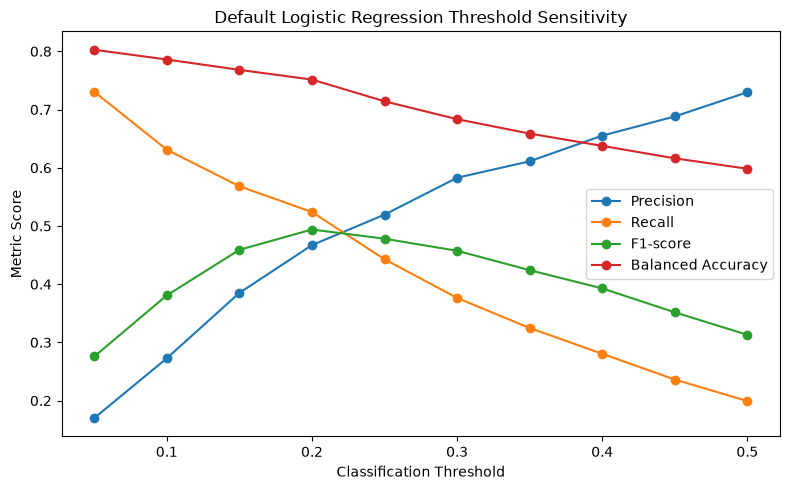

In [52]:
# ---------------------------------------------------------
# Default Logistic Regression from Stage 4
# ---------------------------------------------------------

default_pipeline = Pipeline(
    steps=[
        (
            "preprocessing",
            preprocessor,
        ),
        (
            "model",
            LogisticRegression(
                max_iter=1000,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)


# ---------------------------------------------------------
# Generate out-of-fold probabilities
# ---------------------------------------------------------

default_probability_oof = cross_val_predict(
    default_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
)[:, 1]


# ---------------------------------------------------------
# Threshold sensitivity
# ---------------------------------------------------------

thresholds = np.arange(
    0.05,
    0.51,
    0.05,
)

threshold_results = pd.DataFrame(
    [
        evaluate_threshold(
            y_train,
            default_probability_oof,
            threshold,
        )
        for threshold in thresholds
    ]
)


print(
    "Default Logistic Regression "
    "— threshold sensitivity:"
)

display(
    threshold_results.round(4)
)


# ---------------------------------------------------------
# Reference candidates
# ---------------------------------------------------------

best_f1_idx = (
    threshold_results[
        "F1-score"
    ].idxmax()
)

best_balanced_idx = (
    threshold_results[
        "Balanced Accuracy"
    ].idxmax()
)


print("\nHighest F1-score candidate:")

display(
    threshold_results.loc[
        [best_f1_idx]
    ].round(4)
)


print(
    "\nHighest balanced-accuracy candidate:"
)

display(
    threshold_results.loc[
        [best_balanced_idx]
    ].round(4)
)


# ---------------------------------------------------------
# Threshold-performance plot
# ---------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Precision"],
    marker="o",
    label="Precision",
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    marker="o",
    label="Recall",
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["F1-score"],
    marker="o",
    label="F1-score",
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Balanced Accuracy"],
    marker="o",
    label="Balanced Accuracy",
)

plt.xlabel(
    "Classification Threshold"
)

plt.ylabel(
    "Metric Score"
)

plt.title(
    "Default Logistic Regression "
    "Threshold Sensitivity"
)

plt.legend()

plt.tight_layout()
plt.show()

## 4. Logistic Regression class-weight comparison

Retain the balanced-weight alternative and its threshold sweep. Increased recall alone does not establish a better operating point: precision and false alarms must also be considered.

In [53]:
# ---------------------------------------------------------
# Balanced Logistic Regression
# ---------------------------------------------------------

balanced_pipeline = Pipeline(
    steps=[
        (
            "preprocessing",
            preprocessor,
        ),
        (
            "model",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)


# ---------------------------------------------------------
# Generate balanced-model out-of-fold probabilities
# ---------------------------------------------------------

balanced_probability_oof = cross_val_predict(
    balanced_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
)[:, 1]


# ---------------------------------------------------------
# Compare default and balanced models at threshold 0.50
# ---------------------------------------------------------

default_05 = evaluate_threshold(
    y_train,
    default_probability_oof,
    0.50,
)

balanced_05 = evaluate_threshold(
    y_train,
    balanced_probability_oof,
    0.50,
)


model_comparison = pd.DataFrame(
    [
        default_05,
        balanced_05,
    ],
    index=[
        "Default Logistic Regression",
        "Balanced Logistic Regression",
    ],
)


# Threshold-independent ranking metrics
model_comparison["ROC-AUC"] = [
    roc_auc_score(
        y_train,
        default_probability_oof,
    ),
    roc_auc_score(
        y_train,
        balanced_probability_oof,
    ),
]

model_comparison["PR-AUC"] = [
    average_precision_score(
        y_train,
        default_probability_oof,
    ),
    average_precision_score(
        y_train,
        balanced_probability_oof,
    ),
]


print(
    "Default vs Balanced Logistic Regression "
    "at threshold 0.50:"
)

display(
    model_comparison.round(4)
)


# ---------------------------------------------------------
# Threshold sensitivity for balanced model
# ---------------------------------------------------------

balanced_threshold_results = pd.DataFrame(
    [
        evaluate_threshold(
            y_train,
            balanced_probability_oof,
            threshold,
        )
        for threshold in thresholds
    ]
)


print(
    "\nBalanced Logistic Regression "
    "— threshold sensitivity:"
)

display(
    balanced_threshold_results.round(4)
)


# ---------------------------------------------------------
# Best balanced-model reference candidates
# ---------------------------------------------------------

balanced_best_f1_idx = (
    balanced_threshold_results[
        "F1-score"
    ].idxmax()
)

balanced_best_balanced_idx = (
    balanced_threshold_results[
        "Balanced Accuracy"
    ].idxmax()
)


print(
    "\nBalanced model — "
    "highest F1-score candidate:"
)

display(
    balanced_threshold_results.loc[
        [balanced_best_f1_idx]
    ].round(4)
)


print(
    "\nBalanced model — "
    "highest balanced-accuracy candidate:"
)

display(
    balanced_threshold_results.loc[
        [balanced_best_balanced_idx]
    ].round(4)
)

Default vs Balanced Logistic Regression at threshold 0.50:


,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,False Positives,False Negatives,True Positives,True Negatives,ROC-AUC,PR-AUC
Default Logistic Regression,0.5,0.9704,0.5983,0.7297,0.1993,0.3130,20,217,54,7709,0.8932,0.4589
Balanced Logistic Regression,0.5,0.8225,0.8138,0.1375,0.8044,0.2349,1367,53,218,6362,0.8955,0.4322



Balanced Logistic Regression — threshold sensitivity:


,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,False Positives,False Negatives,True Positives,True Negatives
0,0.05,0.2470,0.6067,0.0428,0.9926,0.0820,6022,2,269,1707
1,0.10,0.3934,0.6718,0.0515,0.9705,0.0978,4845,8,263,2884
2,0.15,0.4975,0.7168,0.0605,0.9520,0.1138,4007,13,258,3722
3,0.20,0.5776,0.7547,0.0707,0.9446,0.1316,3364,15,256,4365
4,0.25,0.6350,0.7773,0.0799,0.9299,0.1472,2901,19,252,4828
5,0.30,0.6842,0.7903,0.0893,0.9041,0.1625,2500,26,245,5229
6,0.35,0.7245,0.7987,0.0988,0.8782,0.1776,2171,33,238,5558
7,0.40,0.7592,0.8042,0.1091,0.8524,0.1935,1886,40,231,5843
8,0.45,0.7921,0.8052,0.1209,0.8192,0.2107,1614,49,222,6115
9,0.50,0.8225,0.8138,0.1375,0.8044,0.2349,1367,53,218,6362



Balanced model — highest F1-score candidate:


,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,False Positives,False Negatives,True Positives,True Negatives
9,0.5,0.8225,0.8138,0.1375,0.8044,0.2349,1367,53,218,6362



Balanced model — highest balanced-accuracy candidate:


,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,False Positives,False Negatives,True Positives,True Negatives
9,0.5,0.8225,0.8138,0.1375,0.8044,0.2349,1367,53,218,6362


## 4.1 Historical exploratory test evaluation — Logistic Regression

**Previously executed test inspection, not final frozen-model validation.** This earlier benchmark uses default C=1 and no class weighting, with threshold 0.20. Original code and outputs are retained unchanged.

In [54]:
# ---------------------------------------------------------
# Freeze final configuration
# ---------------------------------------------------------

FINAL_THRESHOLD = 0.20

final_pipeline = Pipeline(
    steps=[
        (
            "preprocessing",
            preprocessor,
        ),
        (
            "model",
            LogisticRegression(
                max_iter=1000,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)


# ---------------------------------------------------------
# Fit using the complete development dataset
# ---------------------------------------------------------

final_pipeline.fit(
    X_train,
    y_train,
)


# ---------------------------------------------------------
# Predict probability on untouched test set
# ---------------------------------------------------------

test_probability = final_pipeline.predict_proba(
    X_test
)[:, 1]


# ---------------------------------------------------------
# Apply frozen threshold
# ---------------------------------------------------------

y_test_pred = (
    test_probability >= FINAL_THRESHOLD
).astype(int)


# ---------------------------------------------------------
# Final classification metrics
# ---------------------------------------------------------

final_test_metrics = pd.DataFrame({
    "Score": {
        "Accuracy": accuracy_score(
            y_test,
            y_test_pred,
        ),
        "Balanced Accuracy":
            balanced_accuracy_score(
                y_test,
                y_test_pred,
            ),
        "Precision": precision_score(
            y_test,
            y_test_pred,
            zero_division=0,
        ),
        "Recall": recall_score(
            y_test,
            y_test_pred,
            zero_division=0,
        ),
        "F1-score": f1_score(
            y_test,
            y_test_pred,
            zero_division=0,
        ),
        "ROC-AUC": roc_auc_score(
            y_test,
            test_probability,
        ),
        "PR-AUC": average_precision_score(
            y_test,
            test_probability,
        ),
    }
})


print(
    "Final held-out test performance:"
)

display(
    final_test_metrics.round(4)
)


# ---------------------------------------------------------
# Final confusion matrix
# ---------------------------------------------------------

final_cm = confusion_matrix(
    y_test,
    y_test_pred,
)

tn, fp, fn, tp = final_cm.ravel()

final_cm_df = pd.DataFrame(
    final_cm,
    index=[
        "Actual normal",
        "Actual failure",
    ],
    columns=[
        "Predicted normal",
        "Predicted failure",
    ],
)

print(
    "\nFinal held-out confusion matrix:"
)

display(final_cm_df)


print(
    f"\nFinal threshold: {FINAL_THRESHOLD:.2f}"
)

print(
    f"Actual failures:    {int(y_test.sum())}"
)

print(
    f"Detected failures:  {tp}"
)

print(
    f"Missed failures:    {fn}"
)

print(
    f"False alarms:       {fp}"
)

Final held-out test performance:


,Score
Accuracy,0.9620
Balanced Accuracy,0.7249
Precision,0.4444
Recall,0.4706
F1-score,0.4571
ROC-AUC,0.8995
PR-AUC,0.4215



Final held-out confusion matrix:


,Predicted normal,Predicted failure
Actual normal,1892,40
Actual failure,36,32



Final threshold: 0.20
Actual failures:    68
Detected failures:  32
Missed failures:    36
False alarms:       40


## 4.2 Historical development/test comparison — Logistic Regression

The two rows explicitly identify their evaluation basis. The test row belongs to the earlier exploratory evaluation.

In [55]:
# ---------------------------------------------------------
# Development performance of selected threshold
# ---------------------------------------------------------

development_selected = evaluate_threshold(
    y_train,
    default_probability_oof,
    FINAL_THRESHOLD,
)


# ---------------------------------------------------------
# Final-test performance
# ---------------------------------------------------------

test_selected = evaluate_threshold(
    y_test,
    test_probability,
    FINAL_THRESHOLD,
)


comparison = pd.DataFrame(
    [
        development_selected,
        test_selected,
    ],
    index=[
        "Development CV",
        "Held-out Test",
    ],
)


comparison["ROC-AUC"] = [
    roc_auc_score(
        y_train,
        default_probability_oof,
    ),
    roc_auc_score(
        y_test,
        test_probability,
    ),
]

comparison["PR-AUC"] = [
    average_precision_score(
        y_train,
        default_probability_oof,
    ),
    average_precision_score(
        y_test,
        test_probability,
    ),
]


print(
    "Selected-model validation comparison:"
)

display(
    comparison.round(4)
)

Selected-model validation comparison:


,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,False Positives,False Negatives,True Positives,True Negatives,ROC-AUC,PR-AUC
Development CV,0.2,0.9636,0.7515,0.4671,0.5240,0.4939,162,129,142,7567,0.8932,0.4589
Held-out Test,0.2,0.9620,0.7249,0.4444,0.4706,0.4571,40,36,32,1892,0.8995,0.4215


### Why try a Decision Tree?

A tree splits operating conditions using thresholds, such as torque or rotational speed, and assigns a failure probability to the resulting leaf. It can capture interactions that a linear model may miss. Deep trees may memorise small groups, so **training vs validation evidence** matters more than training accuracy.

## 5. Initial Decision Tree investigation: depths 2–6

The original experiment pools five-fold OOF probabilities for each depth. Its PR-AUC values are not fold-mean PR-AUC values.

In [56]:
from time import perf_counter

from sklearn.tree import DecisionTreeClassifier


# ---------------------------------------------------------
# Tree-specific preprocessing
# ---------------------------------------------------------
# Scaling is not required for a Decision Tree.
# Numerical variables are passed through unchanged,
# while Type is one-hot encoded.

tree_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            "passthrough",
            NUMERIC_FEATURES,
        ),
        (
            "categorical",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore",
            ),
            CATEGORICAL_FEATURES,
        ),
    ]
)


# ---------------------------------------------------------
# Controlled depth experiment
# ---------------------------------------------------------

TREE_THRESHOLD = 0.50

depth_values = [
    2,
    3,
    4,
    5,
    6,
]

tree_results = []
tree_probabilities = {}


for depth in depth_values:

    tree_pipeline = Pipeline(
        steps=[
            (
                "preprocessing",
                tree_preprocessor,
            ),
            (
                "model",
                DecisionTreeClassifier(
                    max_depth=depth,
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    )

    start_time = perf_counter()

    probability_oof = cross_val_predict(
        tree_pipeline,
        X_train,
        y_train,
        cv=cv,
        method="predict_proba",
    )[:, 1]

    runtime = perf_counter() - start_time

    tree_probabilities[depth] = probability_oof

    metrics = evaluate_threshold(
        y_train,
        probability_oof,
        TREE_THRESHOLD,
    )

    metrics["Max Depth"] = depth

    metrics["ROC-AUC"] = roc_auc_score(
        y_train,
        probability_oof,
    )

    metrics["PR-AUC"] = average_precision_score(
        y_train,
        probability_oof,
    )

    metrics["CV Runtime [s]"] = runtime

    tree_results.append(metrics)


tree_results = pd.DataFrame(
    tree_results
)


# Put useful columns first
tree_results = tree_results[
    [
        "Max Depth",
        "Accuracy",
        "Balanced Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC",
        "PR-AUC",
        "False Positives",
        "False Negatives",
        "True Positives",
        "True Negatives",
        "CV Runtime [s]",
    ]
]


print(
    "Decision Tree depth sensitivity "
    "(5-fold cross-validation):"
)

display(
    tree_results.round(4)
)

Decision Tree depth sensitivity (5-fold cross-validation):


,Max Depth,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,False Positives,False Negatives,True Positives,True Negatives,CV Runtime [s]
0,2,0.9718,0.6062,0.8169,0.2140,0.3392,0.6374,0.2651,13,213,58,7716,0.0926
1,3,0.9730,0.6193,0.8667,0.2399,0.3757,0.7997,0.3593,10,206,65,7719,0.1244
2,4,0.9736,0.6321,0.8571,0.2657,0.4056,0.9055,0.4829,12,199,72,7717,0.1325
3,5,0.9755,0.6811,0.8049,0.3653,0.5025,0.9219,0.5713,24,172,99,7705,0.1610
4,6,0.9770,0.7264,0.7702,0.4576,0.5741,0.9189,0.5962,37,147,124,7692,0.1328


## 5.1 Initial candidate selection

Depth 6 led this limited initial sweep; it is an intermediate candidate, not the final selected configuration.

In [57]:
# ---------------------------------------------------------
# Best tree according to PR-AUC
# ---------------------------------------------------------

best_tree_index = (
    tree_results[
        "PR-AUC"
    ].idxmax()
)

best_tree_result = (
    tree_results.loc[
        [best_tree_index]
    ]
)

best_tree_depth = int(
    tree_results.loc[
        best_tree_index,
        "Max Depth"
    ]
)


print(
    "Best Decision Tree candidate "
    "according to PR-AUC:"
)

display(
    best_tree_result.round(4)
)

print(
    f"\nSelected depth for comparison: "
    f"{best_tree_depth}"
)

Best Decision Tree candidate according to PR-AUC:


,Max Depth,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,False Positives,False Negatives,True Positives,True Negatives,CV Runtime [s]
4,6,0.977,0.7264,0.7702,0.4576,0.5741,0.9189,0.5962,37,147,124,7692,0.1328



Selected depth for comparison: 6


## 5.2 Initial development comparison with Logistic Regression

All rows below use development OOF predictions. Both Logistic Regression operating points are retained.

In [58]:
# ---------------------------------------------------------
# Existing Logistic Regression operating points
# ---------------------------------------------------------

logistic_default = evaluate_threshold(
    y_train,
    default_probability_oof,
    0.50,
)

logistic_selected = evaluate_threshold(
    y_train,
    default_probability_oof,
    0.20,
)


# Add threshold-independent metrics
logistic_default["ROC-AUC"] = (
    roc_auc_score(
        y_train,
        default_probability_oof,
    )
)

logistic_default["PR-AUC"] = (
    average_precision_score(
        y_train,
        default_probability_oof,
    )
)

logistic_selected["ROC-AUC"] = (
    logistic_default["ROC-AUC"]
)

logistic_selected["PR-AUC"] = (
    logistic_default["PR-AUC"]
)


# ---------------------------------------------------------
# Best tree metrics
# ---------------------------------------------------------

best_tree_probability = (
    tree_probabilities[
        best_tree_depth
    ]
)

best_tree_metrics = evaluate_threshold(
    y_train,
    best_tree_probability,
    0.50,
)

best_tree_metrics["ROC-AUC"] = (
    roc_auc_score(
        y_train,
        best_tree_probability,
    )
)

best_tree_metrics["PR-AUC"] = (
    average_precision_score(
        y_train,
        best_tree_probability,
    )
)


# ---------------------------------------------------------
# Final development-set comparison
# ---------------------------------------------------------

alternative_comparison = pd.DataFrame(
    [
        logistic_default,
        logistic_selected,
        best_tree_metrics,
    ],
    index=[
        "Logistic Regression — threshold 0.50",
        "Logistic Regression — threshold 0.20",
        f"Decision Tree — depth {best_tree_depth}",
    ],
)


comparison_columns = [
    "Threshold",
    "Accuracy",
    "Balanced Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC",
    "PR-AUC",
    "False Positives",
    "False Negatives",
]


print(
    "Linear-classifier vs nonlinear-model comparison:"
)

display(
    alternative_comparison[
        comparison_columns
    ].round(4)
)

Linear-classifier vs nonlinear-model comparison:


,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,False Positives,False Negatives
Logistic Regression — threshold 0.50,0.5,0.9704,0.5983,0.7297,0.1993,0.3130,0.8932,0.4589,20,217
Logistic Regression — threshold 0.20,0.2,0.9636,0.7515,0.4671,0.5240,0.4939,0.8932,0.4589,162,129
Decision Tree — depth 6,0.5,0.9770,0.7264,0.7702,0.4576,0.5741,0.9189,0.5962,37,147


## 5.3 Initial tree threshold sensitivity

The initial depth-6 tree favoured approximately 0.30 on development F1. Keep the original floating-point np.arange thresholds: rounded labels can conceal tiny boundary differences from literal 0.50, explaining small count differences between historical tables.

In [59]:
# ---------------------------------------------------------
# Threshold sensitivity for selected Decision Tree
# ---------------------------------------------------------

tree_thresholds = np.arange(
    0.10,
    0.51,
    0.05,
)

tree_threshold_results = pd.DataFrame(
    [
        evaluate_threshold(
            y_train,
            best_tree_probability,
            threshold,
        )
        for threshold in tree_thresholds
    ]
)


print(
    f"Decision Tree depth {best_tree_depth} "
    "— threshold sensitivity:"
)

display(
    tree_threshold_results.round(4)
)


# ---------------------------------------------------------
# Best F1 operating point
# ---------------------------------------------------------

tree_best_f1_idx = (
    tree_threshold_results[
        "F1-score"
    ].idxmax()
)

print(
    "\nDecision Tree — highest F1-score operating point:"
)

display(
    tree_threshold_results.loc[
        [tree_best_f1_idx]
    ].round(4)
)

Decision Tree depth 6 — threshold sensitivity:


,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,False Positives,False Negatives,True Positives,True Negatives
0,0.10,0.9441,0.8696,0.3543,0.7897,0.4891,390,57,214,7339
1,0.15,0.9605,0.8460,0.4485,0.7232,0.5537,241,75,196,7488
2,0.20,0.9634,0.8244,0.4716,0.6753,0.5554,205,88,183,7524
3,0.25,0.9762,0.7563,0.7015,0.5203,0.5975,60,130,141,7669
4,0.30,0.9769,0.7566,0.7194,0.5203,0.6039,55,130,141,7674
5,0.35,0.9764,0.7439,0.7204,0.4945,0.5864,52,137,134,7677
6,0.40,0.9769,0.7352,0.7500,0.4760,0.5824,43,142,129,7686
7,0.45,0.9769,0.7352,0.7500,0.4760,0.5824,43,142,129,7686
8,0.50,0.9771,0.7265,0.7750,0.4576,0.5754,36,147,124,7693



Decision Tree — highest F1-score operating point:


,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,False Positives,False Negatives,True Positives,True Negatives
4,0.3,0.9769,0.7566,0.7194,0.5203,0.6039,55,130,141,7674


## 5.4 Historical exploratory test evaluation — depth-6 tree

**Previously executed test inspection.** Depth 6 and threshold 0.30 are superseded experimental settings. They are preserved as history and must not be mistaken for the frozen depth-9/leaf-10 model.

In [60]:
# ---------------------------------------------------------
# Final nonlinear candidate
# ---------------------------------------------------------

FINAL_TREE_DEPTH = 6
FINAL_TREE_THRESHOLD = 0.30

final_tree_pipeline = Pipeline(
    steps=[
        (
            "preprocessing",
            tree_preprocessor,
        ),
        (
            "model",
            DecisionTreeClassifier(
                max_depth=FINAL_TREE_DEPTH,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)


# Fit using development data only
final_tree_pipeline.fit(
    X_train,
    y_train,
)


# Failure probabilities on held-out test set
tree_test_probability = (
    final_tree_pipeline.predict_proba(
        X_test
    )[:, 1]
)


# Frozen decision threshold
tree_test_prediction = (
    tree_test_probability
    >= FINAL_TREE_THRESHOLD
).astype(int)


# Performance
tree_test_metrics = evaluate_threshold(
    y_test,
    tree_test_probability,
    FINAL_TREE_THRESHOLD,
)

tree_test_metrics["ROC-AUC"] = roc_auc_score(
    y_test,
    tree_test_probability,
)

tree_test_metrics["PR-AUC"] = average_precision_score(
    y_test,
    tree_test_probability,
)


tree_test_results = pd.DataFrame(
    [tree_test_metrics],
    index=[
        "Decision Tree — Held-out Test"
    ],
)

display(
    tree_test_results.round(4)
)

,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,False Positives,False Negatives,True Positives,True Negatives,ROC-AUC,PR-AUC
Decision Tree — Held-out Test,0.3,0.9755,0.6894,0.7879,0.3824,0.5149,7,42,26,1925,0.9219,0.5877


## 6. Wider tree-depth sensitivity

Training and validation metrics below are means of individual fold scores. This extends the initial sweep without replacing it.

In [61]:
from sklearn.model_selection import cross_validate


# ---------------------------------------------------------
# Decision Tree complexity analysis
# ---------------------------------------------------------
# The previous experiment stopped at depth 6, where
# validation performance was still improving.
#
# A wider depth range is therefore evaluated to determine
# whether additional complexity improves generalisation
# or begins to cause overfitting.

TREE_DEPTHS = [
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10,
    12,
    None,
]

complexity_results = []


for depth in TREE_DEPTHS:

    pipeline = Pipeline(
        steps=[
            (
                "preprocessing",
                tree_preprocessor,
            ),
            (
                "model",
                DecisionTreeClassifier(
                    max_depth=depth,
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    )

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "pr_auc": "average_precision",
            "roc_auc": "roc_auc",
            "f1": "f1",
            "balanced_accuracy":
                "balanced_accuracy",
        },
        return_train_score=True,
        n_jobs=-1,
    )

    complexity_results.append({
        "Max Depth":
            "None" if depth is None else depth,

        "Train PR-AUC":
            scores["train_pr_auc"].mean(),

        "Validation PR-AUC":
            scores["test_pr_auc"].mean(),

        "Train ROC-AUC":
            scores["train_roc_auc"].mean(),

        "Validation ROC-AUC":
            scores["test_roc_auc"].mean(),

        "Train F1":
            scores["train_f1"].mean(),

        "Validation F1":
            scores["test_f1"].mean(),

        "Validation Balanced Accuracy":
            scores[
                "test_balanced_accuracy"
            ].mean(),
    })


complexity_results = pd.DataFrame(
    complexity_results
)


print(
    "Decision Tree complexity analysis:"
)

display(
    complexity_results.round(4)
)

Decision Tree complexity analysis:


,Max Depth,Train PR-AUC,Validation PR-AUC,Train ROC-AUC,Validation ROC-AUC,Train F1,Validation F1,Validation Balanced Accuracy
0,2,0.2830,0.2429,0.6539,0.6359,0.3665,0.3325,0.6061
1,3,0.3776,0.3191,0.8140,0.7810,0.4005,0.3337,0.6028
2,4,0.5224,0.4349,0.8978,0.8817,0.5022,0.4048,0.6321
3,5,0.6766,0.5369,0.9537,0.9206,0.6081,0.4929,0.6776
4,6,0.7660,0.5759,0.9687,0.9156,0.7149,0.5751,0.7265
5,7,0.8433,0.6394,0.9793,0.9018,0.7918,0.6653,0.7717
6,8,0.9013,0.6336,0.9872,0.8687,0.8792,0.7011,0.8058
7,9,0.9286,0.6244,0.9927,0.8607,0.8987,0.7127,0.8097
8,10,0.9495,0.6186,0.9962,0.8701,0.9298,0.7302,0.8311
9,12,0.9793,0.5698,0.9991,0.8597,0.9577,0.7115,0.8252


## 6.1 Training versus validation PR-AUC: overfitting evidence

Training PR-AUC rises towards 1 while validation PR-AUC peaks near depth 7 and then falls. Additional unrestricted depth does not improve generalisation in this experiment.

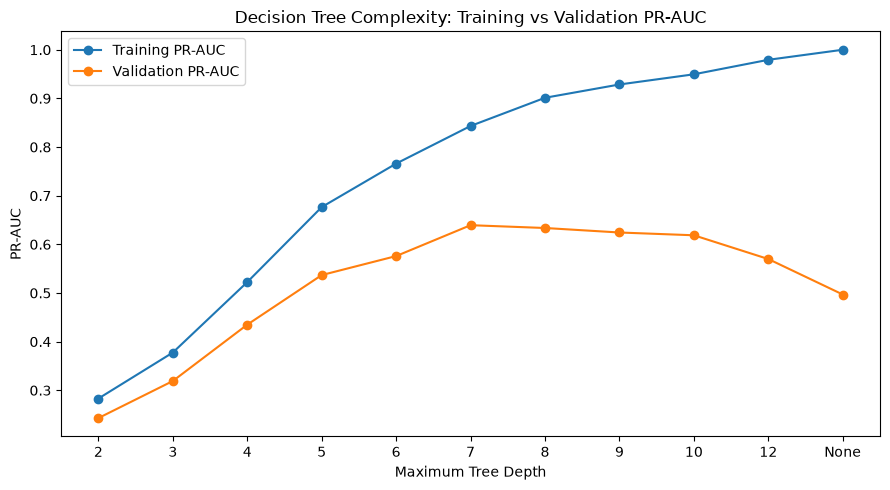

In [62]:
# ---------------------------------------------------------
# Plot training vs validation PR-AUC
# ---------------------------------------------------------

x = np.arange(
    len(complexity_results)
)

labels = (
    complexity_results[
        "Max Depth"
    ].astype(str)
)


plt.figure(figsize=(9, 5))

plt.plot(
    x,
    complexity_results[
        "Train PR-AUC"
    ],
    marker="o",
    label="Training PR-AUC",
)

plt.plot(
    x,
    complexity_results[
        "Validation PR-AUC"
    ],
    marker="o",
    label="Validation PR-AUC",
)

plt.xticks(
    x,
    labels,
)

plt.xlabel(
    "Maximum Tree Depth"
)

plt.ylabel(
    "PR-AUC"
)

plt.title(
    "Decision Tree Complexity: "
    "Training vs Validation PR-AUC"
)

plt.legend()

plt.tight_layout()
plt.show()

## 7. Minimum-leaf-size sensitivity

At depth 7, larger minimum leaves reduce the training/validation gap. Leaf 20 has the highest validation PR-AUC in this conditional sweep; it is not yet the final joint choice.

In [63]:
# ---------------------------------------------------------
# Decision Tree minimum-leaf-size sensitivity
# ---------------------------------------------------------
# Depth 7 gave the highest mean validation PR-AUC.
# The next experiment investigates whether preventing
# very small terminal leaves improves generalisation.

LEAF_SIZES = [
    1,
    2,
    5,
    10,
    20,
    40,
]

leaf_results = []


for leaf_size in LEAF_SIZES:

    pipeline = Pipeline(
        steps=[
            (
                "preprocessing",
                tree_preprocessor,
            ),
            (
                "model",
                DecisionTreeClassifier(
                    max_depth=7,
                    min_samples_leaf=leaf_size,
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    )

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "pr_auc": "average_precision",
            "roc_auc": "roc_auc",
            "f1": "f1",
            "balanced_accuracy":
                "balanced_accuracy",
        },
        return_train_score=True,
        n_jobs=-1,
    )

    leaf_results.append({
        "Min Samples Leaf":
            leaf_size,

        "Train PR-AUC":
            scores[
                "train_pr_auc"
            ].mean(),

        "Validation PR-AUC":
            scores[
                "test_pr_auc"
            ].mean(),

        "Train F1":
            scores[
                "train_f1"
            ].mean(),

        "Validation F1":
            scores[
                "test_f1"
            ].mean(),

        "Validation ROC-AUC":
            scores[
                "test_roc_auc"
            ].mean(),

        "Validation Balanced Accuracy":
            scores[
                "test_balanced_accuracy"
            ].mean(),
    })


leaf_results = pd.DataFrame(
    leaf_results
)


print(
    "Decision Tree minimum-leaf-size sensitivity:"
)

display(
    leaf_results.round(4)
)

Decision Tree minimum-leaf-size sensitivity:


,Min Samples Leaf,Train PR-AUC,Validation PR-AUC,Train F1,Validation F1,Validation ROC-AUC,Validation Balanced Accuracy
0,1,0.8433,0.6394,0.7918,0.6653,0.9018,0.7717
1,2,0.8411,0.6530,0.7760,0.6443,0.9193,0.7588
2,5,0.8265,0.6819,0.7484,0.6568,0.9331,0.7712
3,10,0.8167,0.6767,0.7296,0.6297,0.9439,0.7613
4,20,0.7680,0.6869,0.6900,0.6006,0.9664,0.7431
5,40,0.6269,0.5637,0.5597,0.4810,0.9607,0.6921


## 7.1 Leaf-size training/validation curve

Very large leaves eventually reduce both scores, indicating underfitting. Retain the complete curve, including unsuccessful settings.

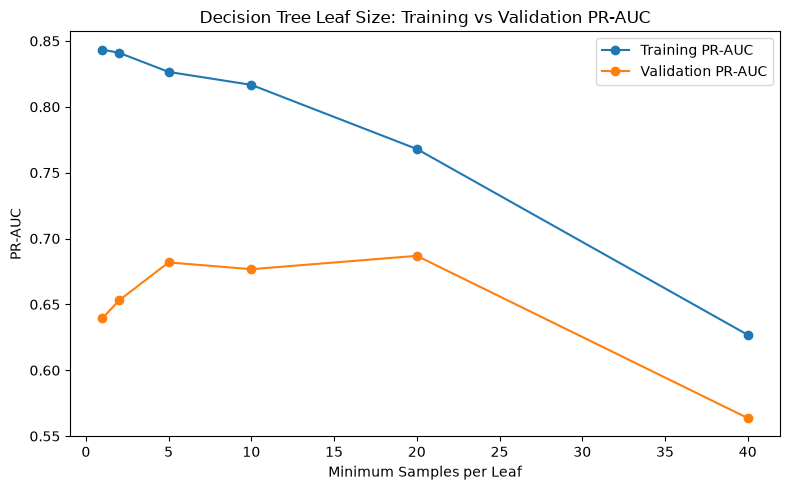

In [64]:
# ---------------------------------------------------------
# Training vs validation PR-AUC
# ---------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    leaf_results[
        "Min Samples Leaf"
    ],
    leaf_results[
        "Train PR-AUC"
    ],
    marker="o",
    label="Training PR-AUC",
)

plt.plot(
    leaf_results[
        "Min Samples Leaf"
    ],
    leaf_results[
        "Validation PR-AUC"
    ],
    marker="o",
    label="Validation PR-AUC",
)

plt.xlabel(
    "Minimum Samples per Leaf"
)

plt.ylabel(
    "PR-AUC"
)

plt.title(
    "Decision Tree Leaf Size: "
    "Training vs Validation PR-AUC"
)

plt.legend()

plt.tight_layout()
plt.show()

## 8. Joint max_depth × min_samples_leaf verification

The targeted joint grid checks interaction between depth and leaf size. Depth 9/leaf 20 leads this single five-fold mean comparison.

In [65]:
# ---------------------------------------------------------
# Joint Decision Tree hyperparameter verification
# ---------------------------------------------------------
# max_depth and min_samples_leaf can interact, so a small
# targeted grid is evaluated around the promising region.

DEPTH_CANDIDATES = [
    6,
    7,
    8,
    9,
]

LEAF_CANDIDATES = [
    5,
    10,
    20,
]

joint_results = []


for depth in DEPTH_CANDIDATES:

    for leaf_size in LEAF_CANDIDATES:

        pipeline = Pipeline(
            steps=[
                (
                    "preprocessing",
                    tree_preprocessor,
                ),
                (
                    "model",
                    DecisionTreeClassifier(
                        max_depth=depth,
                        min_samples_leaf=leaf_size,
                        random_state=RANDOM_STATE,
                    ),
                ),
            ]
        )

        scores = cross_validate(
            pipeline,
            X_train,
            y_train,
            cv=cv,
            scoring={
                "pr_auc": "average_precision",
                "roc_auc": "roc_auc",
                "f1": "f1",
                "balanced_accuracy":
                    "balanced_accuracy",
            },
            return_train_score=True,
            n_jobs=-1,
        )

        joint_results.append({
            "Max Depth":
                depth,

            "Min Samples Leaf":
                leaf_size,

            "Train PR-AUC":
                scores[
                    "train_pr_auc"
                ].mean(),

            "Validation PR-AUC":
                scores[
                    "test_pr_auc"
                ].mean(),

            "Validation ROC-AUC":
                scores[
                    "test_roc_auc"
                ].mean(),

            "Validation F1":
                scores[
                    "test_f1"
                ].mean(),

            "Validation Balanced Accuracy":
                scores[
                    "test_balanced_accuracy"
                ].mean(),
        })


joint_results = pd.DataFrame(
    joint_results
)


joint_results = (
    joint_results
    .sort_values(
        "Validation PR-AUC",
        ascending=False,
    )
    .reset_index(drop=True)
)


print(
    "Joint Decision Tree hyperparameter verification:"
)

display(
    joint_results.round(4)
)


print(
    "\nBest configuration by validation PR-AUC:"
)

display(
    joint_results.head(1).round(4)
)

Joint Decision Tree hyperparameter verification:


,Max Depth,Min Samples Leaf,Train PR-AUC,Validation PR-AUC,Validation ROC-AUC,Validation F1,Validation Balanced Accuracy
0,9,20,0.8016,0.7045,0.9392,0.6439,0.7689
1,9,10,0.8622,0.7026,0.9226,0.6814,0.7927
2,8,10,0.8470,0.7024,0.9309,0.6704,0.7854
3,8,20,0.7909,0.7021,0.9426,0.6439,0.7689
4,8,5,0.8753,0.6986,0.9032,0.7159,0.8133
5,9,5,0.8914,0.6970,0.9010,0.7141,0.8149
6,7,20,0.7680,0.6869,0.9664,0.6006,0.7431
7,7,5,0.8265,0.6819,0.9331,0.6568,0.7712
8,7,10,0.8167,0.6767,0.9439,0.6297,0.7613
9,6,5,0.7557,0.6390,0.9491,0.5993,0.7377



Best configuration by validation PR-AUC:


,Max Depth,Min Samples Leaf,Train PR-AUC,Validation PR-AUC,Validation ROC-AUC,Validation F1,Validation Balanced Accuracy
0,9,20,0.8016,0.7045,0.9392,0.6439,0.7689


## 9. Repeated stratified CV stability comparison

The original 5 folds × 5 repeats comparison ranks depth 9/leaf 10 first by mean PR-AUC (0.6921). This is a small advantage over nearby configurations; the reported fold-score standard deviation is not a confidence interval or a significance test.

In [66]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate


# ---------------------------------------------------------
# Stability verification of leading tree configurations
# ---------------------------------------------------------

TOP_TREE_CONFIGS = [
    (9, 20),
    (9, 10),
    (8, 10),
    (8, 20),
]


repeated_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=RANDOM_STATE,
)


stability_results = []


for depth, leaf_size in TOP_TREE_CONFIGS:

    pipeline = Pipeline(
        steps=[
            (
                "preprocessing",
                tree_preprocessor,
            ),
            (
                "model",
                DecisionTreeClassifier(
                    max_depth=depth,
                    min_samples_leaf=leaf_size,
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    )

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=repeated_cv,
        scoring={
            "pr_auc": "average_precision",
            "roc_auc": "roc_auc",
            "f1": "f1",
            "balanced_accuracy":
                "balanced_accuracy",
        },
        n_jobs=-1,
    )

    stability_results.append({
        "Max Depth":
            depth,

        "Min Samples Leaf":
            leaf_size,

        "Mean PR-AUC":
            scores[
                "test_pr_auc"
            ].mean(),

        "Std PR-AUC":
            scores[
                "test_pr_auc"
            ].std(),

        "Mean ROC-AUC":
            scores[
                "test_roc_auc"
            ].mean(),

        "Mean F1":
            scores[
                "test_f1"
            ].mean(),

        "Mean Balanced Accuracy":
            scores[
                "test_balanced_accuracy"
            ].mean(),
    })


stability_results = pd.DataFrame(
    stability_results
)


stability_results = (
    stability_results
    .sort_values(
        "Mean PR-AUC",
        ascending=False,
    )
    .reset_index(drop=True)
)


display(
    stability_results.round(4)
)

,Max Depth,Min Samples Leaf,Mean PR-AUC,Std PR-AUC,Mean ROC-AUC,Mean F1,Mean Balanced Accuracy
0,9,10,0.6921,0.0563,0.9230,0.6725,0.7985
1,8,20,0.6883,0.0460,0.9388,0.6504,0.7800
2,9,20,0.6882,0.0472,0.9284,0.6504,0.7800
3,8,10,0.6839,0.0566,0.9285,0.6663,0.7931


## 10. Logistic Regression regularisation sensitivity

The original repeated-CV sweep retains C=1 (mean PR-AUC 0.4654). This benchmark is not retuned in Notebook 06.

In [67]:
# ---------------------------------------------------------
# Logistic Regression regularisation sensitivity
# ---------------------------------------------------------
# C controls the inverse strength of L2 regularisation.
# Smaller C = stronger regularisation.
# Larger C = weaker regularisation.

C_VALUES = [
    0.01,
    0.1,
    1.0,
    10.0,
    100.0,
]

logistic_c_results = []


for C_value in C_VALUES:

    pipeline = Pipeline(
        steps=[
            (
                "preprocessing",
                preprocessor,
            ),
            (
                "model",
                LogisticRegression(
                    C=C_value,
                    max_iter=1000,
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    )

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=repeated_cv,
        scoring={
            "pr_auc": "average_precision",
            "roc_auc": "roc_auc",
            "f1": "f1",
            "balanced_accuracy":
                "balanced_accuracy",
        },
        n_jobs=-1,
    )

    logistic_c_results.append({
        "C":
            C_value,

        "Mean PR-AUC":
            scores[
                "test_pr_auc"
            ].mean(),

        "Std PR-AUC":
            scores[
                "test_pr_auc"
            ].std(),

        "Mean ROC-AUC":
            scores[
                "test_roc_auc"
            ].mean(),

        "Mean F1":
            scores[
                "test_f1"
            ].mean(),

        "Mean Balanced Accuracy":
            scores[
                "test_balanced_accuracy"
            ].mean(),
    })


logistic_c_results = pd.DataFrame(
    logistic_c_results
)

logistic_c_results = (
    logistic_c_results
    .sort_values(
        "Mean PR-AUC",
        ascending=False,
    )
    .reset_index(drop=True)
)


print(
    "Logistic Regression regularisation sensitivity:"
)

display(
    logistic_c_results.round(4)
)

Logistic Regression regularisation sensitivity:


,C,Mean PR-AUC,Std PR-AUC,Mean ROC-AUC,Mean F1,Mean Balanced Accuracy
0,1.00,0.4654,0.0399,0.8940,0.3045,0.5954
1,10.00,0.4653,0.0396,0.8939,0.3180,0.6018
2,100.00,0.4651,0.0395,0.8939,0.3205,0.6029
3,0.10,0.4639,0.0391,0.8932,0.2375,0.5687
4,0.01,0.4120,0.0413,0.8399,0.0000,0.5000


## 11. Selected tree structure and development OOF probabilities

Freeze max_depth=9 and min_samples_leaf=10. The following pooled five-fold OOF PR-AUC of 0.7050 and ROC-AUC of 0.9179 are development estimates, distinct from the repeated-fold mean PR-AUC of 0.6921.

In [68]:
# ---------------------------------------------------------
# Final Decision Tree structure
# ---------------------------------------------------------

FINAL_TREE_DEPTH = 9
FINAL_TREE_MIN_LEAF = 10


final_tree_candidate = Pipeline(
    steps=[
        (
            "preprocessing",
            tree_preprocessor,
        ),
        (
            "model",
            DecisionTreeClassifier(
                max_depth=FINAL_TREE_DEPTH,
                min_samples_leaf=FINAL_TREE_MIN_LEAF,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)


# ---------------------------------------------------------
# Out-of-fold probabilities on development data
# ---------------------------------------------------------

final_tree_oof_probability = cross_val_predict(
    final_tree_candidate,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]


print(
    "Final tree OOF probability range:"
)

print(
    f"Minimum: {final_tree_oof_probability.min():.4f}"
)

print(
    f"Maximum: {final_tree_oof_probability.max():.4f}"
)


print(
    "\nThreshold-independent performance:"
)

print(
    "ROC-AUC:",
    round(
        roc_auc_score(
            y_train,
            final_tree_oof_probability,
        ),
        4,
    ),
)

print(
    "PR-AUC:",
    round(
        average_precision_score(
            y_train,
            final_tree_oof_probability,
        ),
        4,
    ),
)

Final tree OOF probability range:
Minimum: 0.0000
Maximum: 1.0000

Threshold-independent performance:
ROC-AUC: 0.9179
PR-AUC: 0.705


## 12. Selected-tree threshold sensitivity: initial range

Retain the original 0.05–0.50 sweep and its actual counts.

In [69]:
# ---------------------------------------------------------
# Final tree threshold sensitivity
# ---------------------------------------------------------

FINAL_TREE_THRESHOLDS = np.arange(
    0.05,
    0.51,
    0.05,
)


final_tree_threshold_results = pd.DataFrame(
    [
        evaluate_threshold(
            y_train,
            final_tree_oof_probability,
            threshold,
        )
        for threshold
        in FINAL_TREE_THRESHOLDS
    ]
)


display(
    final_tree_threshold_results.round(4)
)

,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,False Positives,False Negatives,True Positives,True Negatives
0,0.05,0.9442,0.8964,0.3618,0.8450,0.5066,404,42,229,7325
1,0.10,0.9648,0.8856,0.4876,0.8007,0.6061,228,54,217,7501
2,0.15,0.9681,0.8785,0.5196,0.7823,0.6244,196,59,212,7533
3,0.20,0.9718,0.8697,0.5613,0.7601,0.6458,161,65,206,7568
4,0.25,0.9752,0.8554,0.6137,0.7269,0.6655,124,74,197,7605
5,0.30,0.9774,0.8512,0.6510,0.7159,0.6819,104,77,194,7625
6,0.35,0.9788,0.8484,0.6784,0.7085,0.6931,91,79,192,7638
7,0.40,0.9809,0.8423,0.7287,0.6937,0.7108,70,83,188,7659
8,0.45,0.9816,0.8249,0.7672,0.6568,0.7078,54,93,178,7675
9,0.50,0.9825,0.8254,0.7911,0.6568,0.7177,47,93,178,7682


## 12.1 Provisional highest-F1 operating point

The best value lies at the boundary of this first sweep, motivating the subsequent extension.

In [70]:
# ---------------------------------------------------------
# Highest-F1 operating point
# ---------------------------------------------------------

best_threshold_index = (
    final_tree_threshold_results[
        "F1-score"
    ].idxmax()
)


best_threshold_result = (
    final_tree_threshold_results.loc[
        [best_threshold_index]
    ]
)


print(
    "Highest-F1 Decision Tree operating point:"
)

display(
    best_threshold_result.round(4)
)

Highest-F1 Decision Tree operating point:


,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,False Positives,False Negatives,True Positives,True Negatives
9,0.5,0.9825,0.8254,0.7911,0.6568,0.7177,47,93,178,7682


### Numerical meaning of the threshold search

For each already-generated out-of-fold failure score `p`, the predicted class is `1` when `p >= threshold`; otherwise it is `0`. The model structure and probability ranking do not change. We compare F1, recall, precision and false-alarm counts on **development OOF** predictions. The selected 0.50 cut-off is then *frozen* for Notebook 06.

## 13. Extended threshold sensitivity and operating-point selection

The existing 0.05–0.95 sweep supports threshold 0.50 as the highest-F1 operating point among the tested values. This is an empirical development choice, not a cost-optimal maintenance policy.

In [71]:
# ---------------------------------------------------------
# Extended threshold sensitivity
# ---------------------------------------------------------
# The previous search ended at 0.50, where F1 was still
# highest. The range is extended to check whether the
# optimum lies above the conventional 0.50 threshold.

FINAL_TREE_THRESHOLDS = np.arange(
    0.05,
    0.96,
    0.05,
)


final_tree_threshold_results = pd.DataFrame(
    [
        evaluate_threshold(
            y_train,
            final_tree_oof_probability,
            threshold,
        )
        for threshold in FINAL_TREE_THRESHOLDS
    ]
)


display(
    final_tree_threshold_results.round(4)
)


best_threshold_index = (
    final_tree_threshold_results[
        "F1-score"
    ].idxmax()
)


best_threshold_result = (
    final_tree_threshold_results.loc[
        [best_threshold_index]
    ]
)


print(
    "\nHighest-F1 Decision Tree operating point:"
)

display(
    best_threshold_result.round(4)
)

,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,False Positives,False Negatives,True Positives,True Negatives
0,0.05,0.9442,0.8964,0.3618,0.8450,0.5066,404,42,229,7325
1,0.10,0.9648,0.8856,0.4876,0.8007,0.6061,228,54,217,7501
2,0.15,0.9681,0.8785,0.5196,0.7823,0.6244,196,59,212,7533
3,0.20,0.9718,0.8697,0.5613,0.7601,0.6458,161,65,206,7568
4,0.25,0.9752,0.8554,0.6137,0.7269,0.6655,124,74,197,7605
5,0.30,0.9774,0.8512,0.6510,0.7159,0.6819,104,77,194,7625
6,0.35,0.9788,0.8484,0.6784,0.7085,0.6931,91,79,192,7638
7,0.40,0.9809,0.8423,0.7287,0.6937,0.7108,70,83,188,7659
8,0.45,0.9816,0.8249,0.7672,0.6568,0.7078,54,93,178,7675
9,0.50,0.9825,0.8254,0.7911,0.6568,0.7177,47,93,178,7682



Highest-F1 Decision Tree operating point:


,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,False Positives,False Negatives,True Positives,True Negatives
9,0.5,0.9825,0.8254,0.7911,0.6568,0.7177,47,93,178,7682


## 14. Archived final-tree test inspection (historical)

The pre-existing Decision Tree test-evaluation code and saved outputs are kept here to preserve the analysis history; **this is not an additional independent test**. Notebook 06 reconstructs the frozen evaluation and includes saved test results, a labelled confusion matrix and fixed comparator models. Its saved outputs are historical execution artefacts, not evidence of a newly untouched test set.

In [72]:
# ---------------------------------------------------------
# Final frozen Decision Tree evaluation
# ---------------------------------------------------------

FINAL_TREE_THRESHOLD = 0.50


final_tree_model = Pipeline(
    steps=[
        (
            "preprocessing",
            tree_preprocessor,
        ),
        (
            "model",
            DecisionTreeClassifier(
                max_depth=9,
                min_samples_leaf=10,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)


# Fit on all development data
final_tree_model.fit(
    X_train,
    y_train,
)


# Predict failure probabilities on held-out test data
final_tree_test_probability = (
    final_tree_model.predict_proba(
        X_test
    )[:, 1]
)


# Apply the frozen threshold
final_tree_test_prediction = (
    final_tree_test_probability
    >= FINAL_TREE_THRESHOLD
).astype(int)


# Threshold-dependent test metrics
final_test_metrics = evaluate_threshold(
    y_test,
    final_tree_test_probability,
    FINAL_TREE_THRESHOLD,
)


# Threshold-independent test metrics
final_test_metrics["ROC-AUC"] = (
    roc_auc_score(
        y_test,
        final_tree_test_probability,
    )
)

final_test_metrics["PR-AUC"] = (
    average_precision_score(
        y_test,
        final_tree_test_probability,
    )
)


final_test_results = pd.DataFrame(
    [final_test_metrics],
    index=[
        "Final Tuned Decision Tree"
    ],
)


print(
    "Final frozen Decision Tree — test performance:"
)

display(
    final_test_results.round(4)
)

Final frozen Decision Tree — test performance:


,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,False Positives,False Negatives,True Positives,True Negatives,ROC-AUC,PR-AUC
Final Tuned Decision Tree,0.5,0.9825,0.8207,0.8,0.6471,0.7154,11,24,44,1921,0.8961,0.7601


## Model Selection and Engineering Findings

Model optimisation investigated Logistic Regression thresholds, class weighting and Decision Tree complexity.

Lower thresholds and class weighting improved failure detection but increased false alarms. Decision Trees performed better, although unrestricted trees showed overfitting: strong training results did not translate into equally strong validation results.

Tree depth and minimum leaf size were adjusted to control complexity. Repeated cross-validation supported selecting `max_depth=9` and `min_samples_leaf=10`, achieving mean PR-AUC = 0.6921 compared with 0.4654 for Logistic Regression. Differences between the leading tree configurations were small.

Threshold testing from 0.05 to 0.95 identified 0.50 as the highest-F1 operating point among those tested.

The selected tree achieved development F1 = 0.7177 and PR-AUC = 0.7050. It detected 178 of 271 failures but still missed 93.

**Conclusion:** The regularised Decision Tree provided the strongest observed balance between failure detection and false alarms. Its parameters are now fixed for final evaluation. Earlier test-set inspections remain a validation limitation.

In [74]:
# Frozen handover to Notebook 06 — no fitting, tuning or test evaluation here.
FINAL_TREE_DEPTH = 9
FINAL_TREE_MIN_LEAF = 10
FINAL_TREE_THRESHOLD = 0.50
FINAL_TREE_RANDOM_STATE = 42